In [2]:
from pathlib import Path
import pandas as pd
import numpy as np

file_path = Path(
    r"MIMOTDD_MonteCarlo_Results.xlsx"
)

print("Tìm thấy file Excel:", file_path.exists())

if file_path.exists():
    excel = pd.ExcelFile(file_path)

    print("\nDanh sách các sheet:")
    for sheet in excel.sheet_names:
        print("-", sheet)
else:
    print("Không tìm thấy file Excel. Hãy kiểm tra đường dẫn.")

Tìm thấy file Excel: True

Danh sách các sheet:
- KB1_SE_20cauHinh
- KB1_SINR_20cauHinh
- KB2_SE_20cauHinh
- KB2_SINR_20cauHinh
- KB3_SE_20cauHinh
- KB3_SINR_20cauHinh
- Thong_ke_20_cau_hinh
- So_sanh_tong_the
- So_sanh_M100
- Du_lieu_chi_tiet
- Thong_so_mo_phong


In [3]:
# Đọc dữ liệu SE của kịch bản KB1
kb1_se = pd.read_excel(
    file_path,
    sheet_name="KB1_SE_20cauHinh"
)

# Kiểm tra kích thước bảng
print("Kích thước bảng:", kb1_se.shape)
print("Số cấu hình UE:", kb1_se["Cau_hinh_UE"].nunique())
print("Số dòng dữ liệu:", len(kb1_se))

# Hiển thị 5 cấu hình đầu tiên
display(kb1_se.head())

Kích thước bảng: (20, 31)
Số cấu hình UE: 20
Số dòng dữ liệu: 20


,Cau_hinh_UE,M10_MR,M10_ZF,M10_M-MMSE,M20_MR,M20_ZF,M20_M-MMSE,M30_MR,M30_ZF,M30_M-MMSE,...,M70_M-MMSE,M80_MR,M80_ZF,M80_M-MMSE,M90_MR,M90_ZF,M90_M-MMSE,M100_MR,M100_ZF,M100_M-MMSE
0,1,1.261396,1.716104,1.920222,1.616921,2.491160,2.550074,2.029542,2.927934,2.968440,...,4.002767,3.038395,4.154345,4.163948,3.208338,4.330224,4.338417,3.322170,4.449519,4.457328
1,2,1.271181,5.112533,5.154484,1.806042,6.321237,6.350035,2.157267,6.935426,6.945892,...,8.292449,3.351385,8.473551,8.474225,3.474917,8.639609,8.641309,3.555121,8.782543,8.784619
2,3,1.135351,3.738872,3.857590,1.564413,4.704145,4.740791,1.731107,5.299978,5.327017,...,6.522276,2.755972,6.751976,6.755172,2.875936,6.908894,6.912998,2.953568,7.073155,7.076614
3,4,1.305603,3.409622,3.562984,1.861395,4.643849,4.663430,2.043754,5.261659,5.275063,...,6.517324,2.995332,6.689009,6.692520,3.138791,6.837741,6.842221,3.237270,6.982868,6.984382
4,5,0.964524,1.499252,1.676045,1.386558,2.206611,2.305543,1.628164,2.640235,2.695471,...,3.552351,2.467241,3.654080,3.668773,2.507784,3.783735,3.796221,2.603623,3.887138,3.902275


In [4]:
# Thong ke SE cua KB1 qua 20 cau hinh UE

methods = ["MR", "ZF", "M-MMSE"]
M_values = list(range(10, 101, 10))

summary_rows = []

for M in M_values:
    for method in methods:
        col = f"M{M}_{method}"

        values = pd.to_numeric(
            kb1_se[col],
            errors="coerce"
        ).dropna()

        summary_rows.append({
            "M": M,
            "Phuong_phap": method,
            "So_cau_hinh": values.count(),
            "SE_trung_binh": values.mean(),
            "Do_lech_chuan": values.std(ddof=1),
            "SE_nho_nhat": values.min(),
            "SE_lon_nhat": values.max()
        })

kb1_summary = pd.DataFrame(summary_rows)

print("BANG THONG KE SE - KB1")
display(kb1_summary.round(4))

BANG THONG KE SE - KB1


,M,Phuong_phap,So_cau_hinh,SE_trung_binh,Do_lech_chuan,SE_nho_nhat,SE_lon_nhat
0,10,MR,20,1.1220,0.2054,0.5592,1.4556
1,10,ZF,20,2.4446,1.1661,0.4399,5.1125
2,10,M-MMSE,20,2.6047,1.1379,0.6074,5.1545
3,20,MR,20,1.5755,0.2785,0.8961,2.1618
4,20,ZF,20,3.4045,1.3639,0.9090,6.3212
5,20,M-MMSE,20,3.4561,1.3432,0.9980,6.3500
6,30,MR,20,1.8708,0.3150,1.1245,2.5214
7,30,ZF,20,3.9311,1.4336,1.2075,6.9354
8,30,M-MMSE,20,3.9605,1.4197,1.2635,6.9459
9,40,MR,20,2.1156,0.3821,1.3390,2.8208


In [5]:
display(
    kb1_summary[kb1_summary["M"] == 100].round(4)
)

,M,Phuong_phap,So_cau_hinh,SE_trung_binh,Do_lech_chuan,SE_nho_nhat,SE_lon_nhat
27,100,MR,20,2.9889,0.5613,1.8235,3.9544
28,100,ZF,20,5.5403,1.6244,2.2882,8.7825
29,100,M-MMSE,20,5.5453,1.6215,2.2988,8.7846


In [6]:
# Tao bang SE KB1 theo dinh dang trinh bay bao cao

kb1_report = pd.DataFrame({
    "So anten M": sorted(kb1_summary["M"].unique())
})

for method in ["MR", "ZF", "M-MMSE"]:
    method_data = (
        kb1_summary[
            kb1_summary["Phuong_phap"] == method
        ]
        .set_index("M")
    )

    kb1_report[f"{method} (SE trung binh ± SD)"] = [
        (
            f"{method_data.loc[M, 'SE_trung_binh']:.4f}"
            f" ± {method_data.loc[M, 'Do_lech_chuan']:.4f}"
        )
        for M in kb1_report["So anten M"]
    ]

display(kb1_report)

,So anten M,MR (SE trung binh ± SD),ZF (SE trung binh ± SD),M-MMSE (SE trung binh ± SD)
0,10,1.1220 ± 0.2054,2.4446 ± 1.1661,2.6047 ± 1.1379
1,20,1.5755 ± 0.2785,3.4045 ± 1.3639,3.4561 ± 1.3432
2,30,1.8708 ± 0.3150,3.9311 ± 1.4336,3.9605 ± 1.4197
3,40,2.1156 ± 0.3821,4.3246 ± 1.4822,4.3415 ± 1.4737
4,50,2.3198 ± 0.4279,4.6237 ± 1.5278,4.6357 ± 1.5217
5,60,2.4886 ± 0.4489,4.8647 ± 1.5586,4.8748 ± 1.5530
6,70,2.6265 ± 0.4685,5.0598 ± 1.5757,5.0686 ± 1.5705
7,80,2.7584 ± 0.5115,5.2376 ± 1.5962,5.2442 ± 1.5924
8,90,2.8842 ± 0.5356,5.3992 ± 1.6102,5.4048 ± 1.6071
9,100,2.9889 ± 0.5613,5.5403 ± 1.6244,5.5453 ± 1.6215


In [7]:
# ==================================================
# PHAN TICH KB2: MULTI-CELL, f = 1
# ==================================================

# 1. Doc du lieu SE cua KB2
kb2_se = pd.read_excel(
    file_path,
    sheet_name="KB2_SE_20cauHinh"
)

print("So cau hinh UE:", kb2_se["Cau_hinh_UE"].nunique())
print("Kich thuoc bang:", kb2_se.shape)

# 2. Tinh thong ke qua 20 cau hinh UE
summary_rows = []

for M in M_values:
    for method in methods:
        col = f"M{M}_{method}"

        values = pd.to_numeric(
            kb2_se[col],
            errors="coerce"
        ).dropna()

        summary_rows.append({
            "M": M,
            "Phuong_phap": method,
            "So_cau_hinh": values.count(),
            "SE_trung_binh": values.mean(),
            "Do_lech_chuan": values.std(ddof=1),
            "SE_nho_nhat": values.min(),
            "SE_lon_nhat": values.max()
        })

kb2_summary = pd.DataFrame(summary_rows)

# 3. Tao bang gon de dua vao bao cao
kb2_report = pd.DataFrame({
    "So anten M": M_values
})

for method in methods:
    method_data = (
        kb2_summary[
            kb2_summary["Phuong_phap"] == method
        ]
        .set_index("M")
    )

    kb2_report[f"{method} (SE trung binh ± SD)"] = [
        (
            f"{method_data.loc[M, 'SE_trung_binh']:.4f}"
            f" ± {method_data.loc[M, 'Do_lech_chuan']:.4f}"
        )
        for M in M_values
    ]

print("\nBANG THONG KE SE - KB2")
display(kb2_report)

So cau hinh UE: 20
Kich thuoc bang: (20, 31)

BANG THONG KE SE - KB2


,So anten M,MR (SE trung binh ± SD),ZF (SE trung binh ± SD),M-MMSE (SE trung binh ± SD)
0,10,1.0466 ± 0.1769,2.1718 ± 0.6488,2.3264 ± 0.6420
1,20,1.4606 ± 0.2454,2.9836 ± 0.7930,3.0390 ± 0.7833
2,30,1.7349 ± 0.3066,3.4331 ± 0.8475,3.4627 ± 0.8435
3,40,1.9450 ± 0.3482,3.7456 ± 0.8873,3.7639 ± 0.8846
4,50,2.1222 ± 0.3864,3.9841 ± 0.9189,3.9970 ± 0.9170
5,60,2.2592 ± 0.4053,4.1743 ± 0.9430,4.1836 ± 0.9414
6,70,2.3767 ± 0.4235,4.3336 ± 0.9594,4.3410 ± 0.9579
7,80,2.4921 ± 0.4483,4.4727 ± 0.9792,4.4786 ± 0.9782
8,90,2.5911 ± 0.4664,4.5981 ± 0.9966,4.6031 ± 0.9958
9,100,2.6867 ± 0.4727,4.7089 ± 1.0131,4.7130 ± 1.0123


In [8]:
# ==================================================
# PHAN TICH KB3: MULTI-CELL, f = 4
# ==================================================

# 1. Doc du lieu SE cua KB3
kb3_se = pd.read_excel(
    file_path,
    sheet_name="KB3_SE_20cauHinh"
)

print("So cau hinh UE:", kb3_se["Cau_hinh_UE"].nunique())
print("Kich thuoc bang:", kb3_se.shape)

# 2. Tinh thong ke qua 20 cau hinh UE
summary_rows = []

for M in M_values:
    for method in methods:
        col = f"M{M}_{method}"

        values = pd.to_numeric(
            kb3_se[col],
            errors="coerce"
        ).dropna()

        summary_rows.append({
            "M": M,
            "Phuong_phap": method,
            "So_cau_hinh": values.count(),
            "SE_trung_binh": values.mean(),
            "Do_lech_chuan": values.std(ddof=1),
            "SE_nho_nhat": values.min(),
            "SE_lon_nhat": values.max()
        })

kb3_summary = pd.DataFrame(summary_rows)

# 3. Tao bang de dua vao bao cao
kb3_report = pd.DataFrame({
    "So anten M": M_values
})

for method in methods:
    method_data = (
        kb3_summary[
            kb3_summary["Phuong_phap"] == method
        ]
        .set_index("M")
    )

    kb3_report[
        f"{method} (SE trung binh ± SD)"
    ] = [
        (
            f"{method_data.loc[M, 'SE_trung_binh']:.4f}"
            f" ± {method_data.loc[M, 'Do_lech_chuan']:.4f}"
        )
        for M in M_values
    ]

print("\nBANG THONG KE SE - KB3")
display(kb3_report)

So cau hinh UE: 20
Kich thuoc bang: (20, 31)

BANG THONG KE SE - KB3


,So anten M,MR (SE trung binh ± SD),ZF (SE trung binh ± SD),M-MMSE (SE trung binh ± SD)
0,10,1.0606 ± 0.1151,2.3025 ± 0.5563,2.4988 ± 0.5410
1,20,1.5298 ± 0.1426,3.2255 ± 0.6255,3.3555 ± 0.6122
2,30,1.8485 ± 0.1697,3.7283 ± 0.6565,3.8582 ± 0.6429
3,40,2.0870 ± 0.1779,4.0874 ± 0.6718,4.2194 ± 0.6601
4,50,2.2851 ± 0.1980,4.3686 ± 0.6857,4.5040 ± 0.6751
5,60,2.4707 ± 0.2173,4.5964 ± 0.6920,4.7353 ± 0.6827
6,70,2.6229 ± 0.2331,4.7894 ± 0.7008,4.9315 ± 0.6893
7,80,2.7488 ± 0.2467,4.9561 ± 0.7083,5.1023 ± 0.6946
8,90,2.8662 ± 0.2598,5.1039 ± 0.7129,5.2522 ± 0.6981
9,100,2.9660 ± 0.2760,5.2360 ± 0.7166,5.3881 ± 0.7005


In [9]:
# ==================================================
# BANG SO SANH TONG THE KB1 - KB2 - KB3
# ==================================================

scenario_summaries = {
    "KB1": kb1_summary,
    "KB2": kb2_summary,
    "KB3": kb3_summary,
}

overall_report = pd.DataFrame({
    "So anten M": M_values
})

for scenario, summary in scenario_summaries.items():
    for method in methods:

        method_data = (
            summary[
                summary["Phuong_phap"] == method
            ]
            .set_index("M")
        )

        overall_report[f"{scenario}_{method}"] = [
            (
                f"{method_data.loc[M, 'SE_trung_binh']:.4f}"
                f" ± {method_data.loc[M, 'Do_lech_chuan']:.4f}"
            )
            for M in M_values
        ]

print("BANG SO SANH TONG THE - SE (bit/s/Hz)")
display(overall_report)

BANG SO SANH TONG THE - SE (bit/s/Hz)


,So anten M,KB1_MR,KB1_ZF,KB1_M-MMSE,KB2_MR,KB2_ZF,KB2_M-MMSE,KB3_MR,KB3_ZF,KB3_M-MMSE
0,10,1.1220 ± 0.2054,2.4446 ± 1.1661,2.6047 ± 1.1379,1.0466 ± 0.1769,2.1718 ± 0.6488,2.3264 ± 0.6420,1.0606 ± 0.1151,2.3025 ± 0.5563,2.4988 ± 0.5410
1,20,1.5755 ± 0.2785,3.4045 ± 1.3639,3.4561 ± 1.3432,1.4606 ± 0.2454,2.9836 ± 0.7930,3.0390 ± 0.7833,1.5298 ± 0.1426,3.2255 ± 0.6255,3.3555 ± 0.6122
2,30,1.8708 ± 0.3150,3.9311 ± 1.4336,3.9605 ± 1.4197,1.7349 ± 0.3066,3.4331 ± 0.8475,3.4627 ± 0.8435,1.8485 ± 0.1697,3.7283 ± 0.6565,3.8582 ± 0.6429
3,40,2.1156 ± 0.3821,4.3246 ± 1.4822,4.3415 ± 1.4737,1.9450 ± 0.3482,3.7456 ± 0.8873,3.7639 ± 0.8846,2.0870 ± 0.1779,4.0874 ± 0.6718,4.2194 ± 0.6601
4,50,2.3198 ± 0.4279,4.6237 ± 1.5278,4.6357 ± 1.5217,2.1222 ± 0.3864,3.9841 ± 0.9189,3.9970 ± 0.9170,2.2851 ± 0.1980,4.3686 ± 0.6857,4.5040 ± 0.6751
5,60,2.4886 ± 0.4489,4.8647 ± 1.5586,4.8748 ± 1.5530,2.2592 ± 0.4053,4.1743 ± 0.9430,4.1836 ± 0.9414,2.4707 ± 0.2173,4.5964 ± 0.6920,4.7353 ± 0.6827
6,70,2.6265 ± 0.4685,5.0598 ± 1.5757,5.0686 ± 1.5705,2.3767 ± 0.4235,4.3336 ± 0.9594,4.3410 ± 0.9579,2.6229 ± 0.2331,4.7894 ± 0.7008,4.9315 ± 0.6893
7,80,2.7584 ± 0.5115,5.2376 ± 1.5962,5.2442 ± 1.5924,2.4921 ± 0.4483,4.4727 ± 0.9792,4.4786 ± 0.9782,2.7488 ± 0.2467,4.9561 ± 0.7083,5.1023 ± 0.6946
8,90,2.8842 ± 0.5356,5.3992 ± 1.6102,5.4048 ± 1.6071,2.5911 ± 0.4664,4.5981 ± 0.9966,4.6031 ± 0.9958,2.8662 ± 0.2598,5.1039 ± 0.7129,5.2522 ± 0.6981
9,100,2.9889 ± 0.5613,5.5403 ± 1.6244,5.5453 ± 1.6215,2.6867 ± 0.4727,4.7089 ± 1.0131,4.7130 ± 1.0123,2.9660 ± 0.2760,5.2360 ± 0.7166,5.3881 ± 0.7005


In [10]:
# ==================================================
# PHAN TICH MUC THAY DOI SE GIUA CAC KICH BAN
# ==================================================

summary_dict = {
    "KB1": kb1_summary,
    "KB2": kb2_summary,
    "KB3": kb3_summary,
}

# Tao bang tra cuu SE trung binh
se_lookup = {}

for scenario, summary in summary_dict.items():
    for method in methods:
        se_lookup[(scenario, method)] = (
            summary[
                summary["Phuong_phap"] == method
            ]
            .set_index("M")["SE_trung_binh"]
        )

# Tinh phan tram thay doi
change_rows = []

for M in M_values:
    for method in methods:

        se_kb1 = se_lookup[("KB1", method)].loc[M]
        se_kb2 = se_lookup[("KB2", method)].loc[M]
        se_kb3 = se_lookup[("KB3", method)].loc[M]

        change_rows.append({
            "M": M,
            "Phuong_phap": method,
            "KB2_vs_KB1_pct": (
                (se_kb2 - se_kb1) / se_kb1 * 100
            ),
            "KB3_vs_KB2_pct": (
                (se_kb3 - se_kb2) / se_kb2 * 100
            ),
            "KB3_vs_KB1_pct": (
                (se_kb3 - se_kb1) / se_kb1 * 100
            ),
        })

change_df = pd.DataFrame(change_rows)

print("MUC THAY DOI SE GIUA CAC KICH BAN (%)")
display(change_df.round(2))

MUC THAY DOI SE GIUA CAC KICH BAN (%)


,M,Phuong_phap,KB2_vs_KB1_pct,KB3_vs_KB2_pct,KB3_vs_KB1_pct
0,10,MR,-6.72,1.35,-5.47
1,10,ZF,-11.16,6.02,-5.81
2,10,M-MMSE,-10.69,7.41,-4.07
3,20,MR,-7.29,4.74,-2.90
4,20,ZF,-12.37,8.11,-5.26
5,20,M-MMSE,-12.07,10.41,-2.91
6,30,MR,-7.26,6.55,-1.19
7,30,ZF,-12.67,8.60,-5.16
8,30,M-MMSE,-12.57,11.42,-2.58
9,40,MR,-8.07,7.30,-1.35


In [11]:
# Tom tat muc thay doi SE tren toan mien M

change_summary = (
    change_df
    .groupby("Phuong_phap")[
        [
            "KB2_vs_KB1_pct",
            "KB3_vs_KB2_pct",
            "KB3_vs_KB1_pct"
        ]
    ]
    .agg(["mean", "min", "max"])
    .round(2)
)

display(change_summary)

KB2_vs_KB1_pct               KB3_vs_KB2_pct               \
                      mean    min    max           mean   min    max   
Phuong_phap                                                            
M-MMSE              -13.54 -15.01 -10.69          12.32  7.41  14.32   
MR                   -8.65 -10.16  -6.72           7.86  1.35  10.62   
ZF                  -13.64 -15.01 -11.16           9.51  6.02  11.19   

            KB3_vs_KB1_pct              
                      mean   min   max  
Phuong_phap                             
M-MMSE               -2.91 -4.07 -2.58  
MR                   -1.50 -5.47 -0.14  
ZF                   -5.44 -5.81 -5.16

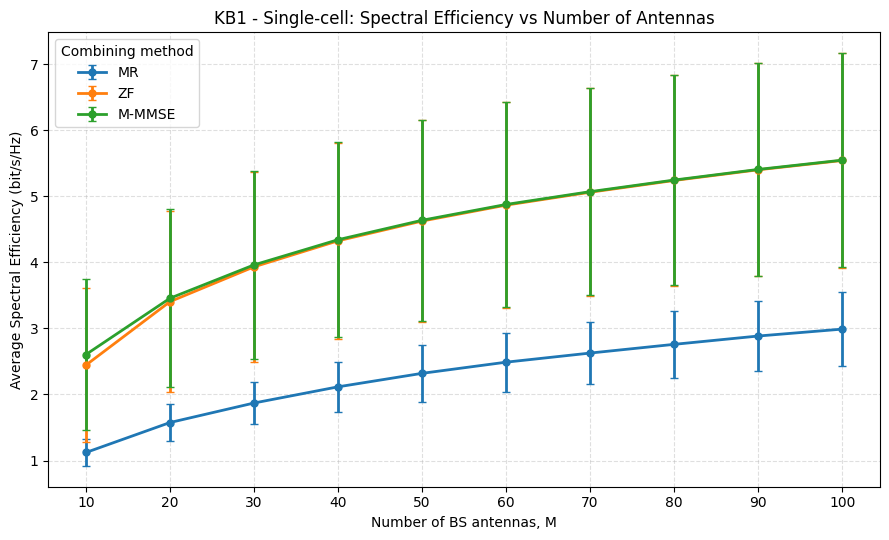

In [12]:
import matplotlib.pyplot as plt

# ==========================================
# DO THI KB1: SE THEO SO ANTEN
# ==========================================

fig, ax = plt.subplots(figsize=(9, 5.5))

for method in methods:
    data = (
        kb1_summary[
            kb1_summary["Phuong_phap"] == method
        ]
        .sort_values("M")
    )

    ax.errorbar(
        data["M"],
        data["SE_trung_binh"],
        yerr=data["Do_lech_chuan"],
        marker="o",
        markersize=5,
        linewidth=2,
        capsize=3,
        label=method
    )

ax.set_title(
    "KB1 - Single-cell: Spectral Efficiency vs Number of Antennas"
)
ax.set_xlabel("Number of BS antennas, M")
ax.set_ylabel("Average Spectral Efficiency (bit/s/Hz)")
ax.set_xticks(M_values)
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend(title="Combining method")
fig.tight_layout()

# Luu anh chat luong cao de dua vao bao cao
output_path = Path

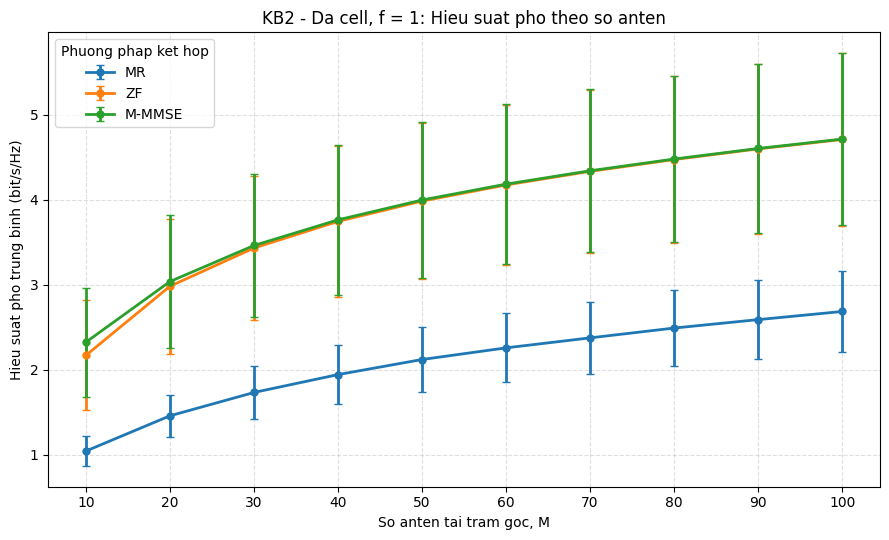

Da luu do thi tai: E:\CODE\MIMOTDD\Hinh_KB2_SE_M.png


In [13]:
# ==========================================
# DO THI KB2: MULTI-CELL, f = 1
# ==========================================

fig, ax = plt.subplots(figsize=(9, 5.5))

for method in methods:
    data = (
        kb2_summary[
            kb2_summary["Phuong_phap"] == method
        ]
        .sort_values("M")
    )

    ax.errorbar(
        data["M"],
        data["SE_trung_binh"],
        yerr=data["Do_lech_chuan"],
        marker="o",
        markersize=5,
        linewidth=2,
        capsize=3,
        label=method
    )

ax.set_title(
    "KB2 - Da cell, f = 1: Hieu suat pho theo so anten"
)
ax.set_xlabel("So anten tai tram goc, M")
ax.set_ylabel("Hieu suat pho trung binh (bit/s/Hz)")
ax.set_xticks(M_values)
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend(title="Phuong phap ket hop")
fig.tight_layout()

output_path = Path(
    r"E:\CODE\MIMOTDD\Hinh_KB2_SE_M.png"
)

fig.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Da luu do thi tai:", output_path)

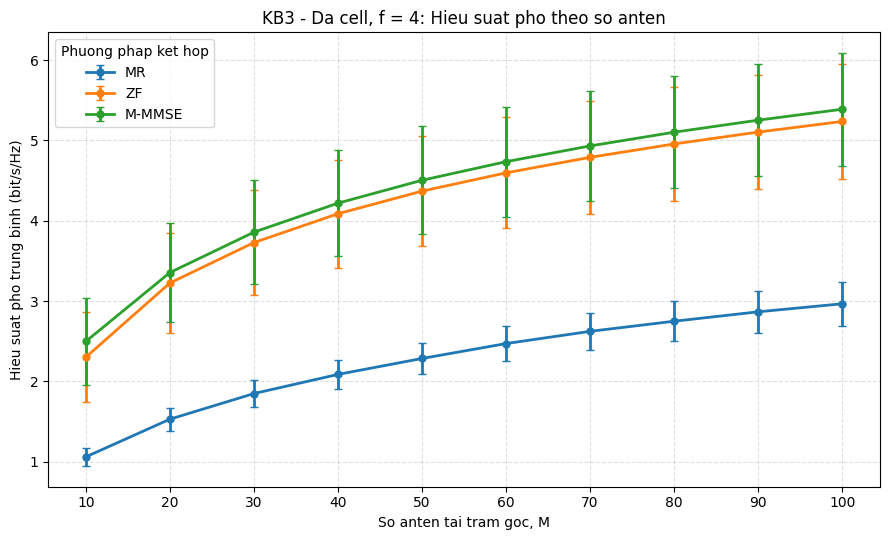

Da luu do thi tai: E:\CODE\MIMOTDD\Hinh_KB3_SE_M.png


In [14]:
# ==========================================
# DO THI KB3: MULTI-CELL, f = 4
# ==========================================

fig, ax = plt.subplots(figsize=(9, 5.5))

for method in methods:
    data = (
        kb3_summary[
            kb3_summary["Phuong_phap"] == method
        ]
        .sort_values("M")
    )

    ax.errorbar(
        data["M"],
        data["SE_trung_binh"],
        yerr=data["Do_lech_chuan"],
        marker="o",
        markersize=5,
        linewidth=2,
        capsize=3,
        label=method
    )

ax.set_title(
    "KB3 - Da cell, f = 4: Hieu suat pho theo so anten"
)
ax.set_xlabel("So anten tai tram goc, M")
ax.set_ylabel("Hieu suat pho trung binh (bit/s/Hz)")
ax.set_xticks(M_values)
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend(title="Phuong phap ket hop")
fig.tight_layout()

output_path = Path(
    r"E:\CODE\MIMOTDD\Hinh_KB3_SE_M.png"
)

fig.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Da luu do thi tai:", output_path)

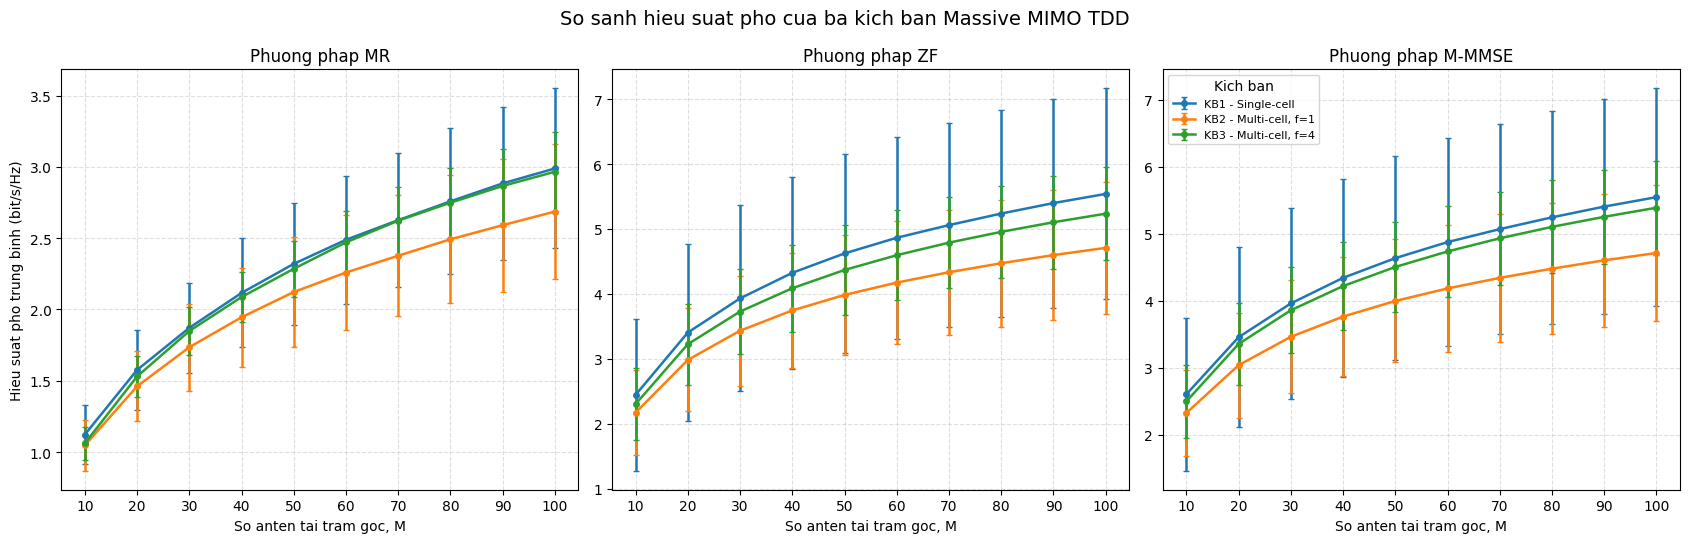

Da luu do thi tai: E:\CODE\MIMOTDD\Hinh_SoSanh_3KichBan_SE_M.png


In [15]:
# ==================================================
# SO SANH TONG THE 3 KICH BAN
# ==================================================

scenario_summaries = {
    "KB1 - Single-cell": kb1_summary,
    "KB2 - Multi-cell, f=1": kb2_summary,
    "KB3 - Multi-cell, f=4": kb3_summary,
}

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5.5),
    sharex=True
)

for ax, method in zip(axes, methods):

    for scenario_name, summary in scenario_summaries.items():

        data = (
            summary[
                summary["Phuong_phap"] == method
            ]
            .sort_values("M")
        )

        ax.errorbar(
            data["M"],
            data["SE_trung_binh"],
            yerr=data["Do_lech_chuan"],
            marker="o",
            markersize=4,
            linewidth=1.8,
            capsize=2,
            label=scenario_name
        )

    ax.set_title(f"Phuong phap {method}")
    ax.set_xlabel("So anten tai tram goc, M")
    ax.set_xticks(M_values)
    ax.grid(True, linestyle="--", alpha=0.4)

axes[0].set_ylabel(
    "Hieu suat pho trung binh (bit/s/Hz)"
)

axes[-1].legend(
    title="Kich ban",
    fontsize=8
)

fig.suptitle(
    "So sanh hieu suat pho cua ba kich ban Massive MIMO TDD",
    fontsize=14
)

fig.tight_layout()

output_path = Path(
    r"E:\CODE\MIMOTDD\Hinh_SoSanh_3KichBan_SE_M.png"
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Da luu do thi tai:", output_path)

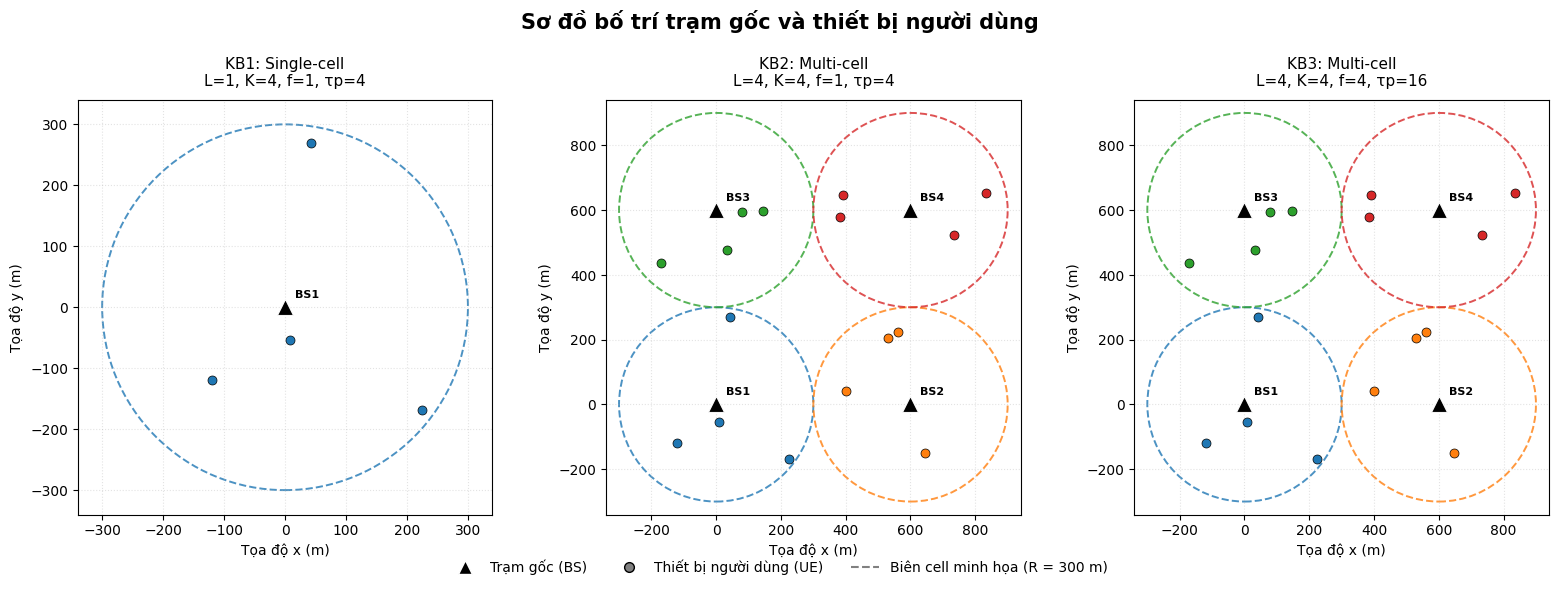

Đã lưu sơ đồ: E:\CODE\MIMOTDD\So_do_bo_tri_BS_UE.png


In [18]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from matplotlib.lines import Line2D
from pathlib import Path

# ==========================================
# SO DO BO TRI BS-UE CHO BA KICH BAN
# ==========================================

R = 300  # Ban kinh cell, met
K = 4    # So UE moi cell

# Tao vi tri UE minh hoa, phan bo deu theo dien tich
rng_layout = np.random.default_rng(7)

def generate_ue_offsets(K, rng):
    angles = rng.uniform(0, 2 * np.pi, K)
    radii = np.sqrt(
        rng.uniform(50**2, R**2, K)
    )
    return np.column_stack((
        radii * np.cos(angles),
        radii * np.sin(angles)
    ))

# Vi tri BS dung trong chuong trinh mo phong
bs_multi = np.array([
    [0, 0],
    [600, 0],
    [0, 600],
    [600, 600]
])

# Tao bo vi tri UE minh hoa cho 4 cell
ue_offsets = [
    generate_ue_offsets(K, rng_layout)
    for _ in range(4)
]

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5.8)
)

fig.suptitle(
    "Sơ đồ bố trí trạm gốc và thiết bị người dùng",
    fontsize=15,
    fontweight="bold"
)

titles = [
    "KB1: Single-cell\nL=1, K=4, f=1, τp=4",
    "KB2: Multi-cell\nL=4, K=4, f=1, τp=4",
    "KB3: Multi-cell\nL=4, K=4, f=4, τp=16"
]

for idx, ax in enumerate(axes):
    ax.set_title(titles[idx], fontsize=11, pad=10)

    if idx == 0:
        # KB1: mot BS tai goc toa do
        bs_positions = np.array([[0, 0]])
        ue_positions = [
            ue_offsets[0]
        ]
    else:
        # KB2 va KB3: bon BS theo luoi 2x2
        bs_positions = bs_multi
        ue_positions = ue_offsets

    # Ve cac cell va UE
    for cell_idx, bs in enumerate(bs_positions):

        # Vung phuc vu minh hoa cua tung BS
        cell = Circle(
            bs,
            R,
            fill=False,
            linestyle="--",
            linewidth=1.4,
            color=f"C{cell_idx}",
            alpha=0.8
        )
        ax.add_patch(cell)

        # Vi tri UE trong cell
        users = bs + ue_positions[cell_idx]

        ax.scatter(
            users[:, 0],
            users[:, 1],
            marker="o",
            s=42,
            color=f"C{cell_idx}",
            edgecolor="black",
            linewidth=0.5,
            zorder=3
        )

        # Vi tri BS
        ax.scatter(
            bs[0],
            bs[1],
            marker="^",
            s=130,
            color="black",
            edgecolor="white",
            linewidth=0.7,
            zorder=4
        )

        ax.annotate(
            f"BS{cell_idx + 1}",
            (bs[0], bs[1]),
            xytext=(7, 7),
            textcoords="offset points",
            fontsize=8,
            fontweight="bold"
        )

    if idx == 0:
        ax.set_xlim(-340, 340)
        ax.set_ylim(-340, 340)
    else:
        ax.set_xlim(-340, 940)
        ax.set_ylim(-340, 940)

    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("Tọa độ x (m)")
    ax.set_ylabel("Tọa độ y (m)")
    ax.grid(True, linestyle=":", alpha=0.35)

# Chu thich chung
legend_handles = [
    Line2D(
        [0], [0],
        marker="^",
        color="w",
        markerfacecolor="black",
        markersize=10,
        label="Trạm gốc (BS)"
    ),
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        markerfacecolor="gray",
        markeredgecolor="black",
        markersize=7,
        label="Thiết bị người dùng (UE)"
    ),
    Line2D(
        [0], [0],
        linestyle="--",
        color="gray",
        label="Biên cell minh họa (R = 300 m)"
    )
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=3,
    frameon=False,
    bbox_to_anchor=(0.5, -0.015)
)

fig.tight_layout(rect=[0, 0.08, 1, 0.92])

# Luu hinh vao thu muc du an
output_path = Path(
    r"E:\CODE\MIMOTDD\So_do_bo_tri_BS_UE.png"
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Đã lưu sơ đồ:", output_path)